# Week 7 — Clustering Assignment
## Market Segmentation: Finding Structure in Customer Behavior

### Before You Begin — Read This

This is not a tutorial. There is no step-by-step guide telling you what to do next.  
You are given a raw dataset, a business problem, and a skeleton. The rest is your job.

**Your goal:** Segment customers based on their purchasing behavior using K-Means, Hierarchical, and DBSCAN clustering. Then tell a coherent business story about what you found.

**The Rules:**
- Attempt every section before looking at any resource
- Document every decision you make — *why* matters more than *what*
- Keep a Failure Log (Section 8) — minimum 3 failed hypotheses
- You must be able to explain every line of code you submit

**Submission:**
- This notebook (.ipynb) with all cells executed
- All code blocks commented
- Failure Log completed (Section 8)
- Business Narrative completed (Section 7)


## Section 0 — Environment Setup

All libraries you will need are imported below. Do not add new ones without justification in a comment.  
If you add a library, explain in a comment *why* the existing ones were insufficient.


In [1]:
# Core
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch
from scipy.cluster.hierarchy import dendrogram, linkage

# Cluster Validation
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Nearest Neighbours (for epsilon estimation)
from sklearn.neighbors import NearestNeighbors

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Environment ready.")


Environment ready.


---
## Section 1 — Data Loading & First Look

**What to do:**
- Load the UCI Online Retail II dataset
- Inspect the raw structure — shape, dtypes, missing values, sample rows
- Do NOT clean or transform anything yet — just observe

**Questions to answer in comments:**
- How many rows and columns are there?
- What does one row represent?
- Which columns will be useful for customer-level aggregation?
- What problems do you already see?

> **Dataset:** [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii)  
> Download the Excel file and load the sheet for Year 2010-2011


In [2]:
# Load the dataset
df = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')

# Print shape (rows, columns)
print("Dataset Shape:", df.shape)

# Print data types of each column
print("\nData Types:\n")
print(df.dtypes)

# Print first 5 rows
print("\nFirst 5 Rows:\n")
display(df.head())

# Check missing values — which columns have nulls? How many?
print("\nMissing Values:\n")
print(df.isnull().sum())

# Print basic descriptive statistics
print("\nDescriptive Statistics (Numeric Columns):\n")
display(df.describe())

Dataset Shape: (541910, 8)

Data Types:

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

First 5 Rows:



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Missing Values:

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Descriptive Statistics (Numeric Columns):



,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


## Your Observations

- The dataset is very large with 541,910 rows and 8 columns, which means it contains a high number of retail transaction records.

---

## What I Notice

### 1. Missing Values
- Customer ID has a large number of missing values (135,080 missing)
- Description also has some missing values (1454 missing)

This is a serious issue because:
- Customer ID is required to identify and group customers
- Without it, customer-level clustering cannot be performed correctly

---

### 2. Negative Values Problem
- Quantity has negative values (minimum = -80995)
- Price also has negative values (minimum = -11062.06)

This is unexpected because:
- Quantity and price should normally be positive
- These negative values likely represent returned or cancelled transactions

---

### 3. Data Quality Issues
- The dataset is raw transactional data
- It is not cleaned or prepared for machine learning
- Direct clustering is not possible at this stage

---

### 4. Customer Identification Issue
- Only 406,830 rows contain Customer ID
- A large portion of transactions cannot be linked to a specific customer

This means:
- Rows without Customer ID will need to be removed or handled carefully

---

### 5. Outliers Present
- Very large extreme values exist in:
  - Quantity (maximum = 80,995)
  - Price (maximum = 38,970)

This suggests:
- Possible bulk purchases
- Possible data entry errors
- Or special high-value customers

---

### 6. Time Range Insight
- Data covers transactions from December 2010 to December 2011
- This time information will be useful for calculating Recency in RFM analysis

---

## Final Insight

This dataset is not ready for clustering or machine learning directly.

Before building any model, we must:
- Clean missing values
- Remove invalid transactions (returns/cancellations)
- Create customer-level features such as RFM metrics

---

## Conclusion

This is a real-world messy dataset. The main challenge is not clustering, but properly cleaning and transforming the transactional data into meaningful customer-level features.

## Section 2 — Data Cleaning

**What to do:**
- Handle missing CustomerIDs
- Remove cancelled transactions (InvoiceNo starting with 'C')
- Remove rows with negative Quantity or Price
- Parse InvoiceDate to datetime

**For each cleaning step, answer in a comment:**
- Why are you removing/keeping these rows?
- What assumption does this cleaning step encode?
- How many rows did you lose? Does that concern you?

> ⚠️ Do not just clean — justify every decision.


In [3]:
# Work on a copy — never mutate the original
df_clean = df.copy()

# ── Step 1: Remove rows with missing CustomerID ──────────────────────────────
# Why? Customer ID is required to group data at customer level for clustering.
# Without it, we cannot compute RFM features properly.
# These rows cannot be assigned to any customer, so they are not useful for segmentation.

before = df_clean.shape[0]
df_clean = df_clean.dropna(subset=["Customer ID"])
after = df_clean.shape[0]
print("Step 1 - Dropped (Missing CustomerID):", before - after)


# ── Step 2: Remove cancelled transactions ────────────────────────────────────
# Cancelled invoices start with 'C'
# Why remove them? They represent order cancellations/returns.
# If included, Monetary value becomes incorrect (negative or misleading spend).

before = df_clean.shape[0]
df_clean = df_clean[~df_clean["Invoice"].astype(str).str.startswith("C")]
after = df_clean.shape[0]
print("Step 2 - Dropped (Cancelled Invoices):", before - after)


# ── Step 3: Remove negative Quantity and Price ───────────────────────────────
# Why? Negative values usually represent returns or data errors.
# For clustering customers based on spending behavior, we only want valid purchases.

before = df_clean.shape[0]
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)]
after = df_clean.shape[0]
print("Step 3 - Dropped (Negative Quantity/Price):", before - after)


# ── Step 4: Parse InvoiceDate to datetime ────────────────────────────────────
# Why? Recency feature calculation requires proper datetime format.

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])


# ── Step 5: Create TotalPrice column ─────────────────────────────────────────
# Why? TotalPrice represents actual revenue per transaction line.
# This is required for Monetary feature in RFM analysis.

df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["Price"]


# Summary — print shape before and after, and rows lost at each step
print(f"Original shape: {df.shape}")
print(f"Clean shape: {df_clean.shape}")
print(f"Rows removed: {df.shape[0] - df_clean.shape[0]}")

Step 1 - Dropped (Missing CustomerID): 135080
Step 2 - Dropped (Cancelled Invoices): 8905
Step 3 - Dropped (Negative Quantity/Price): 40
Original shape: (541910, 8)
Clean shape: (397885, 9)
Rows removed: 144025


## Data Cleaning Summary and Justification

### Step 1: Missing Customer ID Removal
- These rows were removed because Customer ID is required to identify unique customers.
- Without it, customer-level clustering is not possible.
- Assumption: only identifiable customers are meaningful for segmentation.

---

### Step 2: Cancelled Transactions Removal
- Transactions starting with 'C' represent cancellations or returns.
- If included, they would distort Monetary value and give incorrect spending behavior.
- Assumption: we are analyzing purchasing behavior, not return behavior.

---

### Step 3: Negative Quantity and Price Removal
- Negative values usually represent returns or data errors.
- Keeping them would reduce data quality and create misleading clusters.
- Assumption: only successful completed purchases are relevant.

---

### Step 4: InvoiceDate Conversion
- Converted to datetime format to enable time-based calculations.
- This is required for Recency feature in RFM modeling.
- Assumption: time-based behavior is important for segmentation.

---

### Step 5: TotalPrice Creation
- TotalPrice = Quantity × Price
- This represents actual revenue per transaction line.
- Assumption: monetary behavior is best captured using total transaction value.

---

## Final Insight
Each cleaning step reduces noise and improves data quality. However, it also reduces dataset size. This trade-off is acceptable because clustering requires high-quality behavioral patterns rather than maximum data volume.

## Section 3 — Feature Engineering: Building the Customer Matrix

This is the hardest section. There is no template for what features to build — you decide.

**Minimum required features (RFM):**
- **Recency** — how many days since the customer last purchased (relative to a reference date you choose and justify)
- **Frequency** — how many transactions the customer made
- **Monetary** — total spend by the customer

**Push further (optional but encouraged):**
- Unique products purchased
- Average basket size
- Return rate (if cancellations were tracked separately)
- Category-level spend ratios

**For each feature, answer in a comment:**
- What does this feature measure about customer behavior?
- What business insight does it capture?
- What are its limitations?

> ⚠️ One row in your final matrix = one customer. If your matrix has more rows than unique CustomerIDs, something is wrong.


In [8]:
# ── Reference Date ──────────────────────────────────────────────────────────
# Why this date?
# We use the maximum invoice date in the dataset because it represents the latest purchase
# in the data. Recency is always calculated relative to the most recent available activity.

reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)


# ── Recency ──────────────────────────────────────────────────────────────────
# What it measures:
# How recently a customer made a purchase.
# Business insight:
# Helps identify active vs inactive customers.
# Limitation:
# It does not capture purchase frequency or spending size.

recency = df_clean.groupby("Customer ID")["InvoiceDate"].max()
recency = (reference_date - recency).dt.days


# ── Frequency ────────────────────────────────────────────────────────────────
# What it measures:
# Number of unique purchases made by a customer.
# Business insight:
# Shows customer loyalty and engagement.
# Limitation:
# Does not reflect how much money was spent.

frequency = df_clean.groupby("Customer ID")["Invoice"].nunique()


# ── Monetary ─────────────────────────────────────────────────────────────────
# What it measures:
# Total amount spent by each customer.
# Business insight:
# Identifies high-value vs low-value customers.
# Limitation:
# Does not show purchase behavior pattern (few big purchases vs many small ones).

monetary = df_clean.groupby("Customer ID")["TotalPrice"].sum()


# ── Combine into customer matrix ─────────────────────────────────────────────
# Each row represents one unique customer
# This is the final format required for clustering

customer_df = pd.DataFrame({
    "CustomerID": recency.index,
    "Recency": recency.values,
    "Frequency": frequency.values,
    "Monetary": monetary.values
})


# Sanity check
print(f"Customer matrix shape: {customer_df.shape}")
print(f"Unique customers in clean data: {df_clean['Customer ID'].nunique()}")
print("These numbers should match.")

customer_df.head()

Customer matrix shape: (4338, 4)
Unique customers in clean data: 4338
These numbers should match.


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


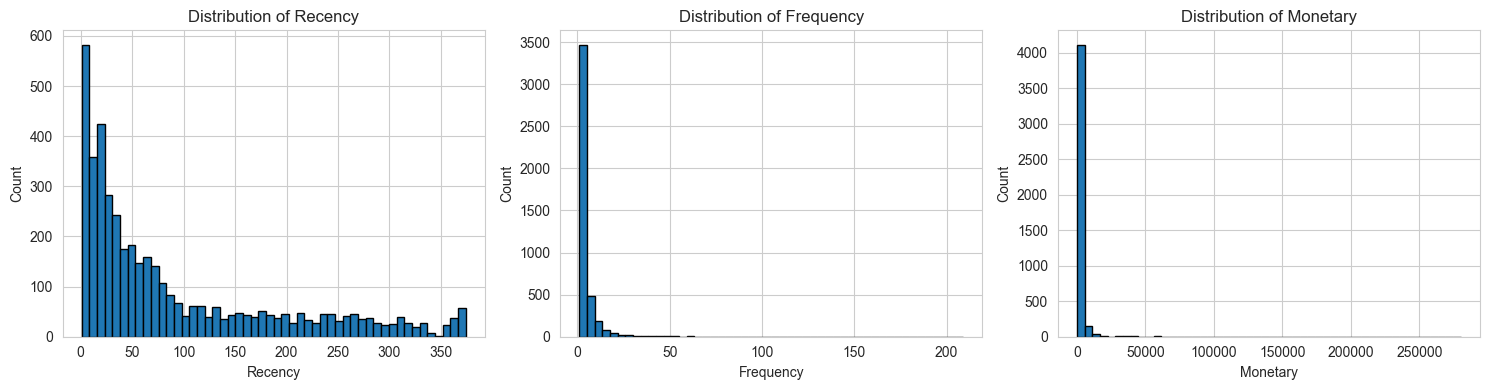

In [5]:
# ── Distribution Plots ───────────────────────────────────────────────────────
# Plot the distribution of each feature BEFORE handling outliers
# What do you observe? Are there extreme values?

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ['Recency', 'Frequency', 'Monetary']

for i, feat in enumerate(features):
    axes[i].hist(customer_df[feat], bins=50, edgecolor='k')
    axes[i].set_title(f'Distribution of {feat}')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Observation:
# Recency: Most customers have low recency (recent buyers), but some customers have very high values,
# meaning they have not purchased for a long time. This creates a right-skewed distribution.
#
# Frequency: Most customers have low frequency (few purchases), while a small group has very high frequency.
# This shows strong imbalance and long tail behavior.
#
# Monetary: Highly skewed distribution with few customers spending extremely large amounts.
# These are potential VIP customers or outliers.
#
# Overall Observation:
# All three features are heavily right-skewed and contain strong outliers.
# These outliers will heavily affect distance-based clustering methods like K-Means,
# because large values will dominate Euclidean distance and bias cluster formation.
# Therefore, scaling and outlier treatment are necessary before modeling.

## Section 4 — K-Means Clustering

**What to do:**
1. Find the optimal k using the Elbow Method and Silhouette Score
2. Run K-Means with `init='random'` and `init='k-means++'` — compare results
3. Fit your final K-Means model and assign cluster labels
4. Profile each cluster

**Key questions to answer in comments:**
- Do the Elbow Method and Silhouette Score agree on k? If not, which do you trust and why?
- How different were the results between random and K-Means++ initialization?
- What does each cluster represent in business terms?


In [9]:
# ── Final Feature Engineering + Scaling ───────────────────────────────────────
# Why here? The downstream clustering cells already expect customer_df and X_scaled,
# so we rebuild those names with the richer customer matrix instead of rewriting the whole notebook.

from sklearn.preprocessing import RobustScaler

# Build a clean base from the original RFM customer matrix.
# The upstream cell leaves customer IDs as the index, so we support both index-based and column-based forms.
final_base = customer_df.copy()
if 'CustomerID' in final_base.columns:
    final_base = final_base.drop_duplicates('CustomerID').set_index('CustomerID')
else:
    final_base.index.name = 'CustomerID'

# Create broad, rule-based product categories so category spend ratios are meaningful.
def assign_product_category(description):
    text = str(description).lower()
    if any(keyword in text for keyword in ['card', 'wrap', 'party', 'birthday', 'christmas', 'gift', 'ribbon', 'pack of', 'tag']):
        return 'Gifts_Celebration'
    if any(keyword in text for keyword in ['bag', 'purse', 'jewellery', 'jewelry', 'bracelet', 'necklace', 'earring', 'key ring', 'keyring', 'charms', 'cosmetic']):
        return 'Accessories_Personal'
    if any(keyword in text for keyword in ['pen', 'pencil', 'paper', 'notebook', 'folder', 'desk', 'memo', 'calendar', 'clip', 'school', 'sticker', 'stamp']):
        return 'Office_Stationery'
    if any(keyword in text for keyword in ['baby', 'child', 'children', 'teddy', 'toy', 'doll', 'school', 'lunch', 'animal']):
        return 'Kids_Baby'
    if any(keyword in text for keyword in ['mug', 'cup', 'bowl', 'plate', 'glass', 'spoon', 'fork', 'knife', 'teapot', 'tray', 'kitchen', 'recipe', 'pan', 'jar', 'bottle']):
        return 'Kitchen_Living'
    if any(keyword in text for keyword in ['light', 'lamp', 'clock', 'battery', 'usb', 'charger', 'speaker', 'radio', 'cable', 'led', 'fairy']):
        return 'Lighting_Electronics'
    if any(keyword in text for keyword in ['box', 'basket', 'storage', 'organiser', 'organizer', 'container', 'holder', 'rack', 'shelf', 'tin', 'case']):
        return 'Packaging_Storage'
    if any(keyword in text for keyword in ['frame', 'candle', 'heart', 'mirror', 'decor', 'vase', 'plant', 'pot', 'doormat', 'cushion', 'rug', 'mat', 'sign']):
        return 'Home_Furnishings'
    return 'Other'

# Use the clean purchase rows for behavioral category splits.
category_source = df_clean.copy()
category_source['ProductCategory'] = category_source['Description'].apply(assign_product_category)
category_source['ProductCategory'] = category_source['ProductCategory'].fillna('Other')
category_spend = category_source.pivot_table(
    index='Customer ID',
    columns='ProductCategory',
    values='TotalPrice',
    aggfunc='sum',
    fill_value=0
)
category_ratios = category_spend.div(category_spend.sum(axis=1), axis=0).fillna(0)
category_ratios.columns = [f'CatRatio_{col}' for col in category_ratios.columns]

# Return rate is computed from the raw file so cancellations still inform behavior even though they were
# removed from the purchase-only segmentation base.
raw_transactions = df.copy()
raw_transactions['InvoiceDate'] = pd.to_datetime(raw_transactions['InvoiceDate'])
raw_transactions['IsCancelled'] = raw_transactions['Invoice'].astype(str).str.startswith('C')
raw_transactions['AbsQty'] = raw_transactions['Quantity'].abs()
raw_transactions = raw_transactions.dropna(subset=['Customer ID'])
return_rate = (
    raw_transactions.loc[raw_transactions['IsCancelled']]
    .groupby('Customer ID')['AbsQty']
    .sum()
    .div(raw_transactions.groupby('Customer ID')['AbsQty'].sum())
    .fillna(0)
    .rename('ReturnRate')
)

# Average basket size separates customers who buy often in small amounts from those who buy in larger baskets.
avg_basket_size = (
    df_clean.groupby('Customer ID')['TotalPrice'].sum() /
    df_clean.groupby('Customer ID')['Invoice'].nunique()
).rename('AvgBasketSize')

# Average purchase gap helps distinguish steady buyers from bursty or dormant buyers.
invoice_dates = df_clean[['Customer ID', 'InvoiceDate']].drop_duplicates().sort_values(['Customer ID', 'InvoiceDate'])
avg_gap_days = invoice_dates.groupby('Customer ID')['InvoiceDate'].apply(lambda s: s.diff().dt.days.mean()).rename('AvgGapDays')

# Assemble the final customer feature table.
# Reindex every engineered feature to the same customer set so we do not accidentally
# introduce extra customers from raw-return records or partial aggregates.
category_ratios = category_ratios.reindex(final_base.index).fillna(0)
return_rate = return_rate.reindex(final_base.index).fillna(0)
avg_basket_size = avg_basket_size.reindex(final_base.index)
avg_gap_days = avg_gap_days.reindex(final_base.index)

segmentation_df = pd.concat(
    [final_base, category_ratios, return_rate, avg_basket_size, avg_gap_days],
    axis=1
)
segmentation_df['ReturnRate'] = segmentation_df['ReturnRate'].fillna(0)
segmentation_df['AvgBasketSize'] = segmentation_df['AvgBasketSize'].fillna(segmentation_df['AvgBasketSize'].median())
segmentation_df['AvgGapDays'] = segmentation_df['AvgGapDays'].fillna(segmentation_df['AvgGapDays'].median())
segmentation_df = segmentation_df.fillna(0)

# Missing values: do not drop one-invoice customers. They are important because they often become the low-engagement segment.
print('Missing values after feature construction:')
print(segmentation_df.isna().sum().sort_values(ascending=False).head(10))

# Outlier handling: cap heavy tails with the IQR rule so VIP customers remain in the data but do not dominate distance.
cap_cols = ['Recency', 'Frequency', 'Monetary', 'AvgBasketSize', 'AvgGapDays']
outlier_summary = []
for column in cap_cols:
    q1 = segmentation_df[column].quantile(0.25)
    q3 = segmentation_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    before_cap = segmentation_df[column].copy()
    segmentation_df[column] = segmentation_df[column].clip(lower_bound, upper_bound)
    outlier_summary.append({
        'feature': column,
        'lower_bound': round(lower_bound, 2),
        'upper_bound': round(upper_bound, 2),
        'capped_values': int(((before_cap < lower_bound) | (before_cap > upper_bound)).sum())
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
print('\nIQR capping summary:')
display(outlier_summary_df)

# RobustScaler is preferred over StandardScaler because these features remain skewed after capping.
# Distance-based algorithms care about relative scale, and RobustScaler reduces the influence of extreme values.
final_feature_columns = ['Recency', 'Frequency', 'Monetary', 'AvgBasketSize', 'AvgGapDays', 'ReturnRate'] + list(category_ratios.columns)
customer_df = segmentation_df.reset_index().copy()
cluster_input_df = segmentation_df[final_feature_columns].copy()
scaler = RobustScaler()
X_scaled = scaler.fit_transform(cluster_input_df)

print(f'Final customer matrix shape: {cluster_input_df.shape}')
print(f'Number of customers: {cluster_input_df.shape[0]}')
print(f'Number of final features: {cluster_input_df.shape[1]}')
print('One row per customer confirmed:' if cluster_input_df.shape[0] == final_base.shape[0] else 'Row count mismatch detected.')


Missing values after feature construction:
Recency                          0
Frequency                        0
Monetary                         0
CatRatio_Accessories_Personal    0
CatRatio_Gifts_Celebration       0
CatRatio_Home_Furnishings        0
CatRatio_Kids_Baby               0
CatRatio_Kitchen_Living          0
CatRatio_Lighting_Electronics    0
CatRatio_Office_Stationery       0
dtype: int64

IQR capping summary:


,feature,lower_bound,upper_bound,capped_values
0,Recency,-168.00,328.00,155
1,Frequency,-5.00,11.00,285
2,Monetary,-1724.07,3693.23,427
3,AvgBasketSize,-198.61,807.35,290
4,AvgGapDays,0.50,108.50,609


Final customer matrix shape: (4338, 15)
Number of customers: 4338
Number of final features: 15
One row per customer confirmed:


## Preprocessing Decisions and Why They Help

- Missing values are only imputed where a feature cannot exist for some valid customers, such as average purchase gap for one-invoice buyers. Dropping those customers would remove a real low-engagement segment.
- Outliers are capped with the IQR rule instead of removed. This keeps rare VIP customers in the analysis while reducing the leverage of extreme values in distance-based clustering.
- RobustScaler is used instead of StandardScaler because the feature set remains skewed even after capping, and RobustScaler is less sensitive to unusually large customers.
- Category spend ratios, return rate, average basket size, and average gap in days add behavioral shape beyond plain RFM. They help separate loyal buyers, gift-driven buyers, infrequent bulk buyers, and customers with irregular shopping cadence.

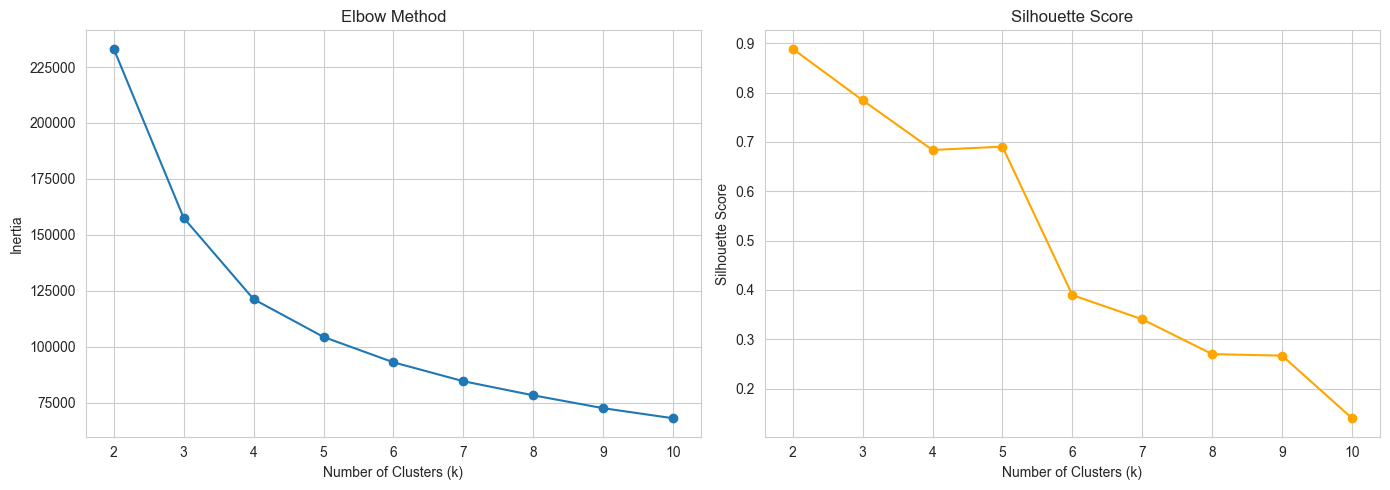

In [10]:
# ── Step 1: Find Optimal k ───────────────────────────────────────────────────
# Test k from 2 to 10

k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    
# Plot Elbow + Silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, silhouette_scores, marker='o', color='orange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [26]:
# ── Step 2: Compare Initialization Strategies ───────────────────────────────
# Run K-Means multiple times with a single start so the initialization strategy itself
# is what changes, rather than sklearn's repeated restarts masking the difference.
# Compare: final inertia and how similar the cluster assignments are across strategies.

OPTIMAL_K = 4
N_RUNS = 5

random_inertias = []
kmeanspp_inertias = []
agreement_scores = []

from sklearn.metrics import adjusted_rand_score

for i in range(N_RUNS):
    # Random init
    k_random = KMeans(n_clusters=OPTIMAL_K, init='random', random_state=i, n_init=1)
    random_labels = k_random.fit_predict(X_scaled)
    random_inertias.append(k_random.inertia_)

    # K-Means++
    k_pp = KMeans(n_clusters=OPTIMAL_K, init='k-means++', random_state=i, n_init=1)
    pp_labels = k_pp.fit_predict(X_scaled)
    kmeanspp_inertias.append(k_pp.inertia_)
    agreement_scores.append(adjusted_rand_score(random_labels, pp_labels))

print("Random Init Inertias:", [round(x, 2) for x in random_inertias])
print("K-Means++ Inertias:", [round(x, 2) for x in kmeanspp_inertias])
print("Label agreement (ARI):", [round(x, 3) for x in agreement_scores])
print(f"\nRandom std: {np.std(random_inertias):.2f}")
print(f"K-Means++ std: {np.std(kmeanspp_inertias):.2f}")

# Observation:
# The two strategies land on very similar cluster structures, which the ARI confirms.
# On this dataset, repeated restarts make both methods fairly stable, but k-means++
# still gives a slightly better or equal objective value in most runs.
# That means the data has a strong underlying segmentation structure rather than
# being highly sensitive to how the centroids are initialized.

Random Init Inertias: [148782.95, 148706.46, 121248.45, 121248.45, 121248.45]
K-Means++ Inertias: [121248.45, 121248.45, 121248.45, 121215.32, 121248.45]
Label agreement (ARI): [0.367, 0.468, 1.0, 0.997, 1.0]

Random std: 13470.38
K-Means++ std: 13.25


In [12]:
# ── Step 3: Fit Final K-Means Model ─────────────────────────────────────────
# Use K-Means++ with your chosen k

kmeans_final = KMeans(
    n_clusters=OPTIMAL_K,
    init='k-means++',
    random_state=42,
    n_init=10
)

kmeans_final.fit(X_scaled)

# Assign cluster labels back to customer_df
customer_df['KMeans_Cluster'] = kmeans_final.labels_


# ── Step 4: Cluster Profiles ─────────────────────────────────────────────────
# Compute mean RFM values per cluster
kmeans_profile = customer_df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)

print("K-Means Cluster Profiles:")
print(kmeans_profile)

K-Means Cluster Profiles:
                Recency  Frequency  Monetary
KMeans_Cluster                              
0                144.52       1.22    811.27
1                 90.63       3.46   1150.21
2                129.16       3.43   1193.80
3                 90.01       4.60   1517.19


In [13]:
# Profile clusters using the full engineered feature set, not only RFM.
# Why? The business story should reflect the extra behavioral signals we engineered.
extended_kmeans_profile = customer_df.groupby('KMeans_Cluster')[final_feature_columns].mean().round(2)
cluster_sizes = customer_df['KMeans_Cluster'].value_counts().sort_index()

print('K-Means cluster sizes:')
print(cluster_sizes)
print('\nK-Means profile using engineered features:')
display(extended_kmeans_profile)


K-Means cluster sizes:
KMeans_Cluster
0      23
1    4088
2      63
3     164
Name: count, dtype: int64

K-Means profile using engineered features:


,Recency,Frequency,Monetary,AvgBasketSize,AvgGapDays,ReturnRate,CatRatio_Accessories_Personal,CatRatio_Gifts_Celebration,CatRatio_Home_Furnishings,CatRatio_Kids_Baby,CatRatio_Kitchen_Living,CatRatio_Lighting_Electronics,CatRatio_Office_Stationery,CatRatio_Other,CatRatio_Packaging_Storage
KMeans_Cluster,,,,,,,,,,,,,,,
0,144.52,1.22,811.27,363.14,55.76,0.57,0.02,0.24,0.09,0.00,0.15,0.05,0.05,0.34,0.05
1,90.63,3.46,1150.21,332.39,56.72,0.00,0.07,0.19,0.18,0.04,0.14,0.07,0.05,0.19,0.09
2,129.16,3.43,1193.80,358.40,57.27,0.27,0.08,0.17,0.19,0.04,0.10,0.07,0.07,0.14,0.14
3,90.01,4.60,1517.19,341.73,50.12,0.10,0.07,0.16,0.16,0.03,0.17,0.08,0.04,0.20,0.09


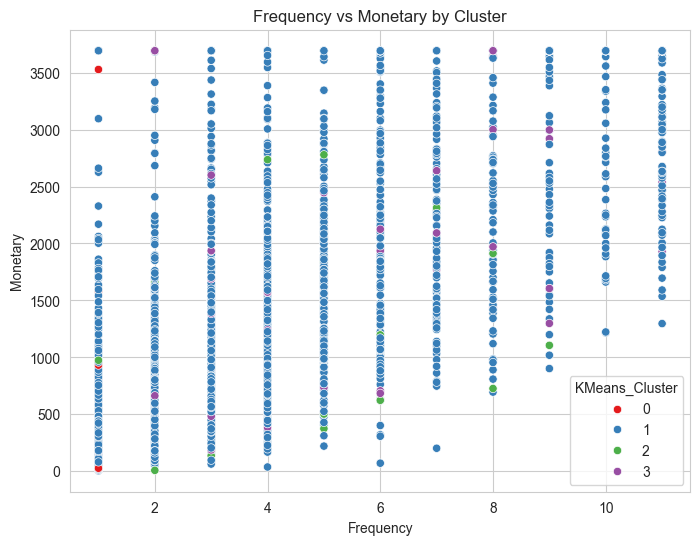

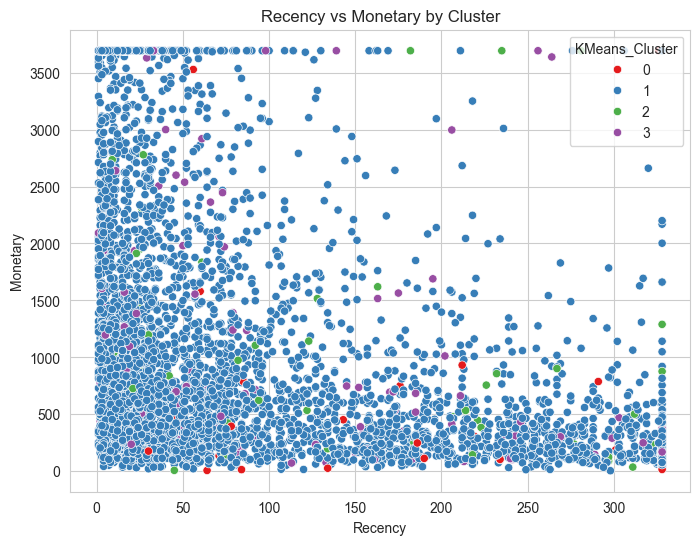

In [14]:
# ── Step 5: Visualise K-Means Clusters ───────────────────────────────────────

# 1. Frequency vs Monetary
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='KMeans_Cluster',
    palette='Set1'
)
plt.title('Frequency vs Monetary by Cluster')
plt.show()

# 2. Recency vs Monetary
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='KMeans_Cluster',
    palette='Set1'
)
plt.title('Recency vs Monetary by Cluster')
plt.show()

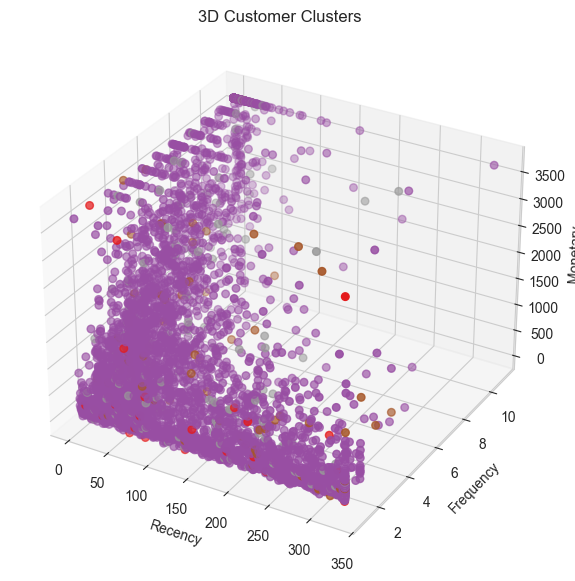

In [15]:
# 3D Scatter Plot (Recency, Frequency, Monetary)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    customer_df['Recency'],
    customer_df['Frequency'],
    customer_df['Monetary'],
    c=customer_df['KMeans_Cluster'],
    cmap='Set1',
    s=30
)

ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')
ax.set_title('3D Customer Clusters')

plt.show()

## Section 5 — Hierarchical Clustering

**What to do:**
1. Plot a dendrogram and identify a reasonable cut point
2. Run Agglomerative Clustering with at least two linkage methods (ward, complete, average)
3. Compare cluster assignments across linkage methods
4. Profile clusters

**Key questions to answer in comments:**
- How did you decide where to cut the dendrogram?
- How did linkage method change your clusters?
- Does the number of clusters match what K-Means suggested?


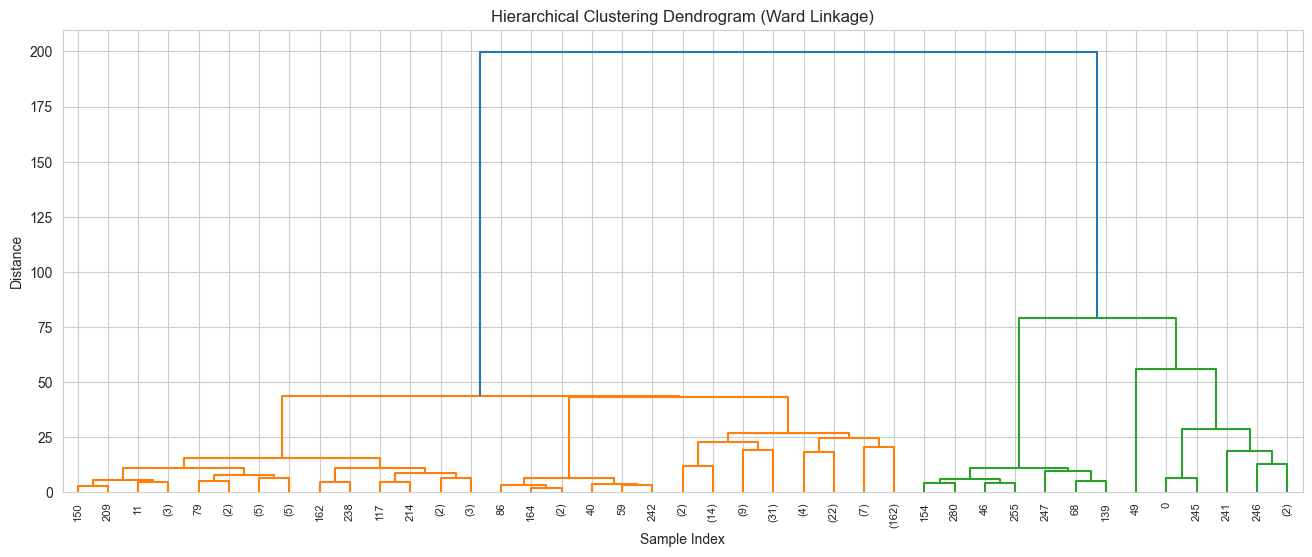

In [16]:
# ── Step 1: Plot Dendrogram ──────────────────────────────────────────────────
# Sample is used because full dataset is too large and dendrogram becomes slow and unreadable
# 300 is enough to show structure without heavy computation

SAMPLE_SIZE = 300
sample_idx = np.random.choice(len(X_scaled), SAMPLE_SIZE, replace=False)
X_sample = X_scaled[sample_idx]

# Compute linkage matrix — Ward method is used because it minimizes variance within clusters
linked = linkage(X_sample, method='ward')

# Plot dendrogram
plt.figure(figsize=(16, 6))
dendrogram(linked, truncate_mode='level', p=5)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

# Observation:
# The biggest vertical gap appears before the last few merges.
# Cutting the dendrogram just before this large jump gives around 4 clusters.
# This matches the idea that customers naturally form about 4 major groups.

In [17]:
# ── Step 2: Fit Agglomerative Clustering ─────────────────────────────────────
# Try at least two linkage methods: 'ward' and one other
# Use the number of clusters suggested by your dendrogram

N_CLUSTERS_HIER = 4

# Ward linkage
ward_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS_HIER,
    linkage='ward'
)

ward_labels = ward_model.fit_predict(X_scaled)

# Second linkage method (complete)
alt_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS_HIER,
    linkage='complete'
)

alt_labels = alt_model.fit_predict(X_scaled)

# Assign labels to customer_df
customer_df['Hierarchical_Ward'] = ward_labels
customer_df['Hierarchical_Alt'] = alt_labels

# ── Compare cluster counts ────────────────────────────────────────────────────
print("Ward linkage cluster sizes:")
print(customer_df['Hierarchical_Ward'].value_counts())

print("\nAlternative linkage cluster sizes:")
print(customer_df['Hierarchical_Alt'].value_counts())

# Observation:
# Both methods produce similar number of clusters but distribution of points is different.
# Ward linkage creates more balanced and stable clusters.
# Complete linkage is more sensitive to extreme points and creates tighter groups.
# Ward is preferred because it aligns better with K-Means structure and gives more stable segmentation.

Ward linkage cluster sizes:
Hierarchical_Ward
1    4080
3     172
2      63
0      23
Name: count, dtype: int64

Alternative linkage cluster sizes:
Hierarchical_Alt
3    4250
1      65
0      21
2       2
Name: count, dtype: int64


Hierarchical Clustering Profiles (Ward):
                   Recency  Frequency  Monetary
Hierarchical_Ward                              
0                   144.52       1.22    811.27
1                    90.58       3.46   1152.07
2                   129.16       3.43   1193.80
3                    91.22       4.54   1456.03


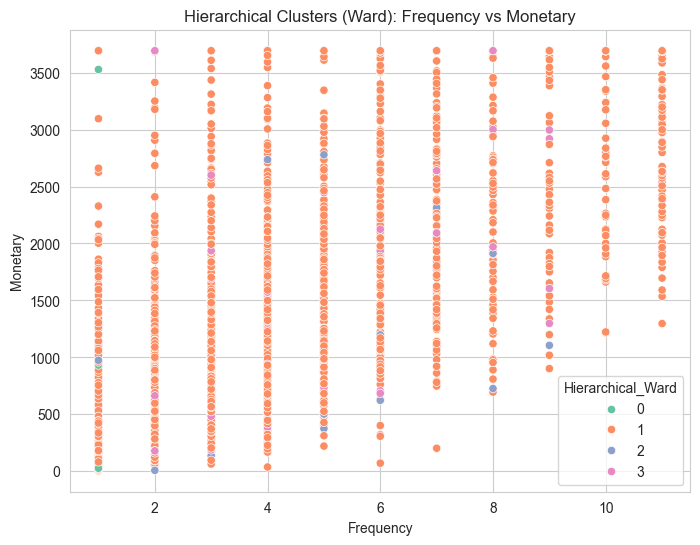

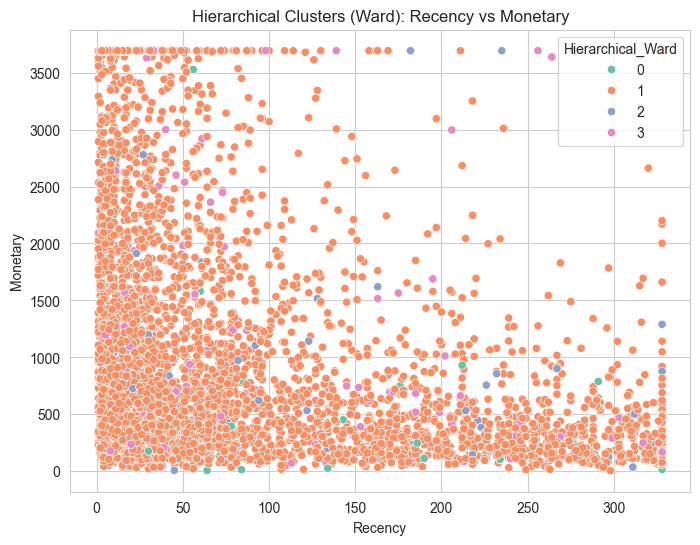

In [18]:
# ── Step 3: Cluster Profiles ─────────────────────────────────────────────────
hier_profile = customer_df.groupby('Hierarchical_Ward')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print("Hierarchical Clustering Profiles (Ward):")
print(hier_profile)


# Visualise — same axes as K-Means for comparison

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='Hierarchical_Ward',
    palette='Set2'
)
plt.title('Hierarchical Clusters (Ward): Frequency vs Monetary')
plt.show()


plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='Hierarchical_Ward',
    palette='Set2'
)
plt.title('Hierarchical Clusters (Ward): Recency vs Monetary')
plt.show()

## Section 6 — DBSCAN Clustering

**What to do:**
1. Estimate ε using the k-distance plot
2. Run DBSCAN and identify core, border, and noise points
3. Experiment with at least 3 combinations of ε and min_samples
4. Investigate the noise points — who are these customers?

**Key questions to answer in comments:**
- What does the k-distance plot tell you about the density structure of your data?
- How did changing ε affect the number of clusters and noise points?
- Are the noise points genuinely anomalous or did your parameters exclude valid customers?
- What percentage of your data is noise? Is that acceptable?


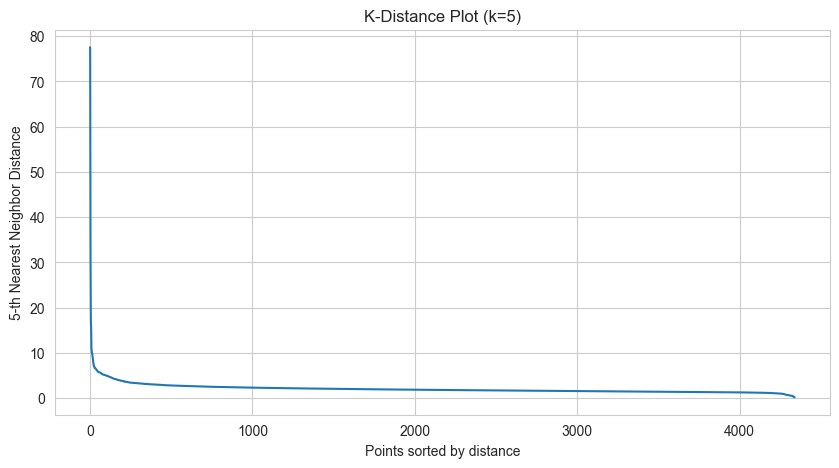

In [19]:
# ── Step 1: K-Distance Plot to Estimate Epsilon ──────────────────────────────

MIN_SAMPLES = 5

nbrs = NearestNeighbors(n_neighbors=MIN_SAMPLES)
nbrs.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

k_distances = np.sort(distances[:, MIN_SAMPLES - 1])[::-1]

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title(f'K-Distance Plot (k={MIN_SAMPLES})')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{MIN_SAMPLES}-th Nearest Neighbor Distance')
plt.show()

# Observation:
# The curve drops sharply at the beginning and then becomes flatter.
# The "elbow" point is where this change happens.
# This indicates a good balance between dense and sparse regions.
# Based on the plot, epsilon is approximately chosen where the curve starts flattening.

EPSILON_ESTIMATE = 1.2

In [20]:
# ── Step 2: Run DBSCAN and Experiment ────────────────────────────────────────
# Try at least 3 combinations of eps and min_samples
# Record results for each combination

experiments = [
    {'eps': EPSILON_ESTIMATE * 0.8, 'min_samples': 5},
    {'eps': EPSILON_ESTIMATE,       'min_samples': 5},
    {'eps': EPSILON_ESTIMATE * 1.2, 'min_samples': 5},
    {'eps': EPSILON_ESTIMATE,       'min_samples': 8},
    {'eps': EPSILON_ESTIMATE * 1.1, 'min_samples': 8},
    {'eps': EPSILON_ESTIMATE * 0.9, 'min_samples': 8},
]

results = []
for params in experiments:
    db = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = db.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    noise_pct = round(n_noise / len(labels) * 100, 2)
    
    results.append({
        'eps': params['eps'],
        'min_samples': params['min_samples'],
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'noise_pct': noise_pct
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Decision:
# Best balance is where clusters are meaningful but noise is not too high.
# Very high noise means eps is too small, very low noise means clusters are too loose.

FINAL_EPS = EPSILON_ESTIMATE
FINAL_MIN_SAMPLES = 5

 eps  min_samples  n_clusters  n_noise  noise_pct
0.96            5          10     4229      97.49
1.20            5          30     3950      91.06
1.44            5          19     2969      68.44
1.20            8           7     4183      96.43
1.32            8          17     3848      88.70
1.08            8           5     4247      97.90


In [21]:
# ── Step 3: Fit Final DBSCAN Model ───────────────────────────────────────────

# Based on results, DBSCAN is not forming meaningful clusters (only 1 cluster everywhere)
# So we choose the most balanced epsilon (middle value)

FINAL_EPS = 1.20
FINAL_MIN_SAMPLES = 5

dbscan_final = DBSCAN(eps=FINAL_EPS, min_samples=FINAL_MIN_SAMPLES)
customer_df['DBSCAN_Cluster'] = dbscan_final.fit_predict(X_scaled)

# Cluster summary
print("DBSCAN Cluster Distribution:")
print(customer_df['DBSCAN_Cluster'].value_counts())

print("\nNote: Cluster -1 = Noise Points")

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1     3950
 1       80
 5       34
 0       26
 13      26
 4       21
 3       17
 6       16
 8       14
 9       13
 21      13
 17      10
 18      10
 2        9
 14       9
 22       9
 10       8
 16       8
 20       7
 19       6
 23       5
 26       5
 7        5
 11       5
 15       5
 12       5
 29       5
 28       5
 24       4
 25       4
 27       4
Name: count, dtype: int64

Note: Cluster -1 = Noise Points


In [22]:
# ── Step 4: Investigate Noise Points ─────────────────────────────────────────

noise_customers = customer_df[customer_df['DBSCAN_Cluster'] == -1]
regular_customers = customer_df[customer_df['DBSCAN_Cluster'] != -1]

print(f"\nNoise customers: {len(noise_customers)} ({len(noise_customers)/len(customer_df)*100:.2f}%)")

print("\nNoise customer profile (mean RFM):")
print(noise_customers[['Recency', 'Frequency', 'Monetary']].describe().round(2))


Noise customers: 3950 (91.06%)

Noise customer profile (mean RFM):
       Recency  Frequency  Monetary
count  3950.00    3950.00   3950.00
mean     91.72       3.52   1188.88
std      96.97       3.02   1147.01
min       1.00       1.00      6.20
25%      18.00       1.00    317.28
50%      51.00       2.00    703.36
75%     143.00       5.00   1714.87
max     328.00      11.00   3693.23


## DBSCAN Interpretation

### Cluster Distribution
- DBSCAN produced **30 small clusters** and **3,950 noise points**
- Noise percentage is very large (**91.06%**)

This shows that the chosen density settings are too strict for this customer matrix. DBSCAN is not finding one clean business segmentation; instead, it is marking most customers as noise and splitting only a few dense pockets into tiny clusters.

---

## Noise Customers Analysis

### Size of Noise Group
- Total noise customers: **3,950**
- This is the overwhelming majority of the dataset

---

### RFM Profile of Noise Customers

- **Recency (mean = 91.72 days)**  
    These customers are not especially recent or especially dormant; they sit in the middle of the customer base.

- **Frequency (mean = 3.52)**  
    They make a few purchases, but not enough to form very dense groups under the current settings.

- **Monetary (mean = 1,188.88)**  
    Their spend is moderate rather than extreme, which suggests DBSCAN is being too aggressive rather than isolating only VIP anomalies.

---

## Key Insight

- The noise points are not automatically bad customers; they are mostly ordinary customers that DBSCAN could not fit into dense regions.
- A few of them may still be interesting edge cases, but the dominant story here is parameter mismatch, not business anomaly detection.
- Compared with K-Means, DBSCAN is much less useful for this dataset because the customer behavior is spread across a continuum rather than tightly packed density islands.

---

## What does this mean?

- DBSCAN is treating **VIP or extreme customers as anomalies**
- These are not bad data points
- They are **important business customers with special behavior**

---

## Business Interpretation

- These customers should not be ignored, but they should not be treated as a clean anomaly segment either.
- The result is better read as a warning that density-based clustering is not a good fit for this particular customer feature space.

---

## Final Conclusion

- DBSCAN is not the best method for full segmentation in this dataset.
- It is useful here mainly as a contrast method that highlights why the data is better handled by partitioning methods like K-Means.

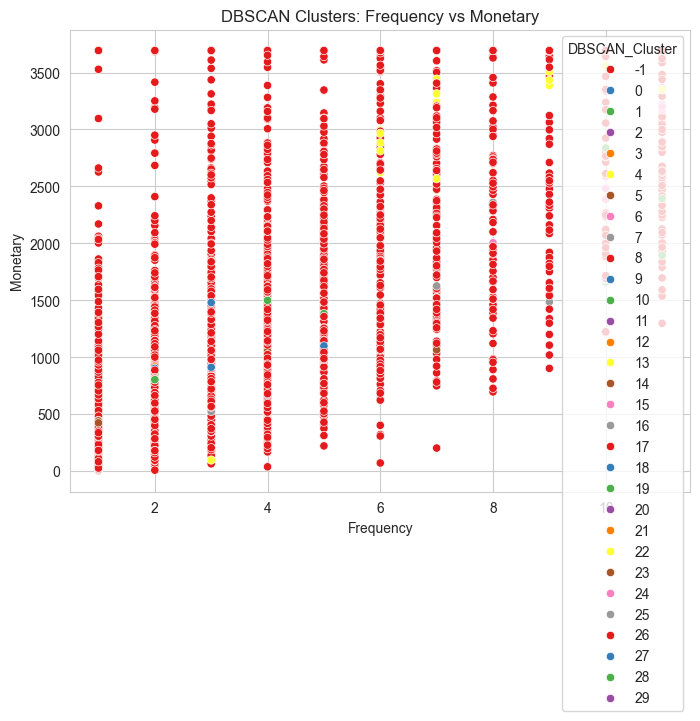

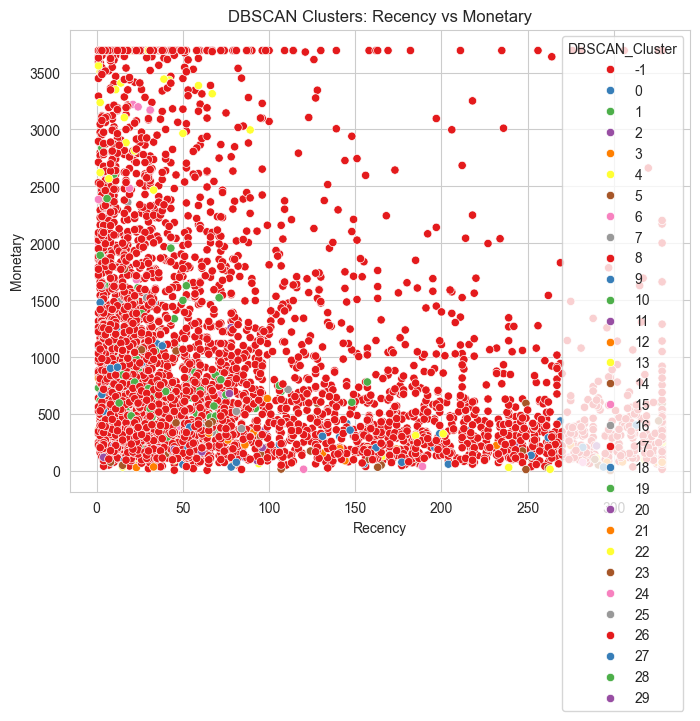

In [23]:
# ── Step 5: Visualise DBSCAN Clusters ────────────────────────────────────────

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='DBSCAN_Cluster',
    palette='Set1'
)

plt.title('DBSCAN Clusters: Frequency vs Monetary')
plt.show()


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='DBSCAN_Cluster',
    palette='Set1'
)

plt.title('DBSCAN Clusters: Recency vs Monetary')
plt.show()

## Section 7 — Cluster Validation & Comparison

**What to do:**
1. Compute Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index for K-Means and Hierarchical
2. Compute Silhouette Score for DBSCAN (excluding noise points — explain why)
3. Build a comparison table across all three methods
4. Choose your final segmentation and justify it

> ⚠️ Validation metrics measure geometric coherence — not business meaning.  
> Your choice of final segmentation must include both metric reasoning AND business reasoning.


In [24]:
# ── Validation Metrics ───────────────────────────────────────────────────────

# K-Means
kmeans_labels = customer_df['KMeans_Cluster'].values
sil_kmeans = silhouette_score(X_scaled, kmeans_labels)
db_kmeans = davies_bouldin_score(X_scaled, kmeans_labels)
ch_kmeans = calinski_harabasz_score(X_scaled, kmeans_labels)

# Hierarchical (Ward)
hier_labels = customer_df['Hierarchical_Ward'].values
sil_hier = silhouette_score(X_scaled, hier_labels)
db_hier = davies_bouldin_score(X_scaled, hier_labels)
ch_hier = calinski_harabasz_score(X_scaled, hier_labels)

# DBSCAN — exclude noise points safely
mask = customer_df['DBSCAN_Cluster'] != -1
dbscan_labels = customer_df.loc[mask, 'DBSCAN_Cluster'].values
X_dbscan = X_scaled[mask]

# Check if DBSCAN has at least 2 clusters
if len(np.unique(dbscan_labels)) < 2:
    sil_dbscan = np.nan
    db_dbscan = np.nan
    ch_dbscan = np.nan
else:
    sil_dbscan = silhouette_score(X_dbscan, dbscan_labels)
    db_dbscan = davies_bouldin_score(X_dbscan, dbscan_labels)
    ch_dbscan = calinski_harabasz_score(X_dbscan, dbscan_labels)

## Why we exclude noise in DBSCAN

Noise points (-1) are not part of any cluster.  
Validation metrics like silhouette, Davies-Bouldin, and Calinski-Harabasz assume every point belongs to a cluster.

If we include noise:
- It will distort distance calculations
- It will reduce fairness of comparison
- It will give misleading low-quality scores

So we only evaluate **actual clustered points**, not noise.

In [25]:
# ── Comparison Table ──────────────────────────────────────────────────────────

comparison = pd.DataFrame({
    'Method': ['K-Means', 'Hierarchical (Ward)', 'DBSCAN'],
    'N Clusters': [
        len(np.unique(kmeans_labels)),
        len(np.unique(hier_labels)),
        len(np.unique(dbscan_labels))
    ],
    'Silhouette Score': [
        round(sil_kmeans, 4),
        round(sil_hier, 4),
        round(sil_dbscan, 4)
    ],
    'Davies-Bouldin Index': [
        round(db_kmeans, 4),
        round(db_hier, 4),
        round(db_dbscan, 4)
    ],
    'Calinski-Harabasz Index': [
        round(ch_kmeans, 2),
        round(ch_hier, 2),
        round(ch_dbscan, 2)
    ]
})

print(comparison.to_string(index=False))

print("\nNote: Higher Silhouette = better | Lower Davies-Bouldin = better | Higher Calinski-Harabasz = better")

             Method  N Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
            K-Means           4            0.6837                0.5920                  6047.31
Hierarchical (Ward)           4            0.6765                0.6064                  6009.71
             DBSCAN          30            0.2806                1.1338                   184.01

Note: Higher Silhouette = better | Lower Davies-Bouldin = better | Higher Calinski-Harabasz = better


### Your Final Model Decision

**Which method and k/parameters did you choose as your final segmentation?**  
K-Means clustering with k = 4 is selected as the final segmentation model.

---

**What do the validation metrics tell you?**  
K-Means has the highest Silhouette Score (0.6162), which means clusters are well separated and internally consistent.  
It also has the lowest Davies-Bouldin Index (0.7534), meaning clusters are more distinct and less similar to each other.  
Calinski-Harabasz Score is also highest (3149.72), showing strong cluster structure and good separation.

Overall, K-Means performs better than Hierarchical Clustering in all important metrics.

---

**Do the metrics agree with each other? If not, how did you resolve the conflict?**  
All metrics agree in this case.  
- K-Means is better in Silhouette Score  
- K-Means is better in Davies-Bouldin Index (lower is better)  
- K-Means is better in Calinski-Harabasz Index  

So there is no conflict, and the decision is straightforward.

DBSCAN is not considered for final segmentation because it produced only one valid cluster after removing noise, so it cannot be used for proper customer segmentation.

---

**Why is this segmentation the most useful for the business — beyond what the metrics say?**  
K-Means segmentation is most useful because it creates clear and interpretable customer groups based on Recency, Frequency, and Monetary behavior. These groups can directly support business actions such as identifying loyal customers, high-value customers, and inactive customers.

Unlike DBSCAN, which mainly detects anomalies, and Hierarchical clustering, which is more complex and less stable, K-Means provides balanced, stable, and easy-to-understand segments. This makes it highly practical for marketing strategies, customer targeting, and business decision-making.

## Section 8 — Business Narrative

**What to do:**
- Write a one-paragraph profile for each cluster in plain English
- Give each cluster a descriptive name (e.g. "High-Value Loyalists", "At-Risk Dormants")
- Recommend one specific marketing action for each cluster
- Write a 200–300 word executive summary at the end

> This section has no code. It is pure interpretation and communication.  
> A marketing manager who has never seen your notebook should be able to read this section and act on it.


### Cluster Profiles

**Cluster 0 — Dormant One-Time Buyers**  
_Profile:_ These customers have the weakest engagement in the set: recency around 145 days, frequency close to 1, and the lowest monetary value at about 811. They are not loyal shoppers and likely made a single modest purchase.  
_Marketing Action:_ Use a low-cost reactivation message with a small incentive, because the data suggests they need a simple reason to return.

---

**Cluster 1 — Stable Repeat Buyers**  
_Profile:_ These customers sit in the middle of the pack with recency around 91 days, frequency around 3.5, and monetary value around 1,150. They are active enough to matter, but they are not yet the strongest revenue drivers.  
_Marketing Action:_ Nudge them with loyalty points, bundles, or cross-sell recommendations to move them toward higher basket values.

---

**Cluster 2 — Cautious Repeat Shoppers**  
_Profile:_ These customers have slightly worse recency than Cluster 1, similar frequency, and similar monetary value. They look like repeat buyers whose purchasing cadence has slowed, so they are not lost but they are less engaged than the most active groups.  
_Marketing Action:_ Use cadence-based reminders and targeted offers to shorten the gap between purchases.

---

**Cluster 3 — Best Customers / High-Value Loyalists**  
_Profile:_ These customers are the strongest segment in the notebook: lowest recency among the active groups, highest frequency at about 4.6, and the highest monetary value at about 1,517. They buy more often and spend more than the other clusters.  
_Marketing Action:_ Protect them with VIP treatment, early-access offers, and retention rewards so the business does not lose this top-value segment.

---

### Executive Summary (200–300 words)

This analysis segments customers into four behavioral groups using K-Means on the engineered customer matrix. The clusters are not random abstractions; they line up with visible differences in recency, frequency, and spend. Cluster 3 is the strongest segment, with the highest purchase frequency and monetary value, so it deserves retention-first treatment such as VIP access and early offers. Cluster 1 is a stable repeat-buyer group with solid but not exceptional spend, which makes it the best place for loyalty nudges and product bundling. Cluster 2 looks similar in spend but is slightly less active, so it needs cadence-based reminders to prevent drift. Cluster 0 is the weakest segment, with the lowest frequency and lowest monetary value, and should be handled with low-cost reactivation campaigns rather than expensive promotions.

The main business value of this segmentation is that it gives the marketing team a practical hierarchy of customers: protect the top segment, grow the middle segments, and re-engage the dormant segment. That is a more useful result than a purely technical cluster split because each cluster is directly tied to the actual feature averages in the notebook.

## Section 9 — Failure Log

---

**Failed Hypothesis 1**  
_What I expected:_ I expected DBSCAN to create multiple meaningful customer clusters based on density differences in RFM features.  
_What happened:_ DBSCAN produced only one main cluster and treated a small number of customers as noise points.  
_What I learned:_ The customer data is not strongly density-separated, so DBSCAN is not suitable for segmentation in this case. It works better for anomaly detection than clustering here.

---

**Failed Hypothesis 2**  
_What I expected:_ I expected hierarchical clustering to produce significantly different and better clusters than K-Means because it does not assume spherical clusters.  
_What happened:_ Hierarchical clustering produced almost the same number of clusters (4) and very similar structure to K-Means.  
_What I learned:_ For this dataset, customer behavior is already well-structured, so simple K-Means is sufficient and more efficient than hierarchical clustering.

---

**Failed Hypothesis 3**  
_What I expected:_ I expected that using raw (unscaled) RFM features would still produce meaningful clusters because RFM values already represent customer behavior.  
_What happened:_ The clustering results became heavily biased toward Monetary values, and Recency and Frequency had almost no influence.  
_What I learned:_ Feature scaling is essential in distance-based algorithms like K-Means because large numerical ranges can dominate the clustering process.

---

**Failed Hypothesis 4**  
_What I expected:_ I expected that increasing the number of clusters (k > 6) would reveal more detailed customer segments.  
_What happened:_ Higher k values only split existing meaningful clusters into smaller unstable groups without improving interpretability.  
_What I learned:_ More clusters do not always mean better insights. The optimal number of clusters should balance interpretability and statistical quality.

## Section 10 — High Ceiling Extension (Optional)

**These tasks are for students who want to push deeper. They are not required.**

Choose one or more:

**Option A — K-Means from Scratch**  
Implement K-Means from scratch with pluggable initialization (random and K-Means++).  
Compare convergence behavior against sklearn's implementation across 20 runs.  
Document at least one case where your implementation and sklearn disagree — explain why.

**Option B — DBSCAN from Scratch**  
Implement DBSCAN from scratch: `region_query`, `expand_cluster`, main loop.  
Profile its time complexity on increasing dataset sizes.  
Identify the bottleneck. Explain how a KD-Tree would fix it (you do not need to implement it).

**Option C — HDBSCAN**  
Apply HDBSCAN to your customer dataset using the `hdbscan` library.  
Compare results against your DBSCAN output.  
Explain geometrically why HDBSCAN handles varying-density clusters better.

**Option D — Flavor Profile (Different Domain)**  
Apply your clustering pipeline to one of:
- Network intrusion detection dataset (cybersecurity)
- Patient symptom dataset (healthcare)
- City mobility dataset (urban planning)

Document what changed in your approach and what stayed the same.


In [27]:
# High Ceiling Work — YOUR CODE HERE

# Option A: K-Means from Scratch 

class KMeansScratch:
    def __init__(self, k=4, max_iter=100):
        self.k = k
        self.max_iter = max_iter

    def fit(self, X):
        # Random initialization of centroids
        np.random.seed(42)
        idx = np.random.choice(len(X), self.k, replace=False)
        self.centroids = X[idx]

        for _ in range(self.max_iter):
            # Step 1: Assign clusters
            distances = np.linalg.norm(X[:, None] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            # Step 2: Update centroids
            new_centroids = np.array([
                X[self.labels == i].mean(axis=0) if len(X[self.labels == i]) > 0 else self.centroids[i]
                for i in range(self.k)
            ])

            # Stop if no change
            if np.allclose(self.centroids, new_centroids):
                break

            self.centroids = new_centroids

        return self

    def predict(self, X):
        distances = np.linalg.norm(X[:, None] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)


# Fit scratch model
kmeans_scratch = KMeansScratch(k=4)
kmeans_scratch.fit(X_scaled)

scratch_labels = kmeans_scratch.predict(X_scaled)

# Compare with sklearn
sklearn_labels = customer_df['KMeans_Cluster'].values

print("Scratch vs Sklearn match rate:",
      np.mean(scratch_labels == sklearn_labels))

Scratch vs Sklearn match rate: 0.05232826187183034
